# Datos socio demográficos y de recursos de salud a nivel de condado de EE. UU. (2018-2019)

In [52]:
#Librerias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import root_mean_squared_error, r2_score
import numpy as np

## Paso 1: Carga del conjunto de datos a tu modelo

In [2]:
df = pd.read_csv('https://breathecode.herokuapp.com/asset/internal-link?id=733&path=demographic_health_data.csv')

df.head()

,fips,TOT_POP,0-9,0-9 y/o % of total pop,19-Oct,10-19 y/o % of total pop,20-29,20-29 y/o % of total pop,30-39,30-39 y/o % of total pop,...,COPD_number,diabetes_prevalence,diabetes_Lower 95% CI,diabetes_Upper 95% CI,diabetes_number,CKD_prevalence,CKD_Lower 95% CI,CKD_Upper 95% CI,CKD_number,Urban_rural_code
0,1001,55601,6787,12.206615,7637,13.735364,6878,12.370281,7089,12.749771,...,3644,12.9,11.9,13.8,5462,3.1,2.9,3.3,1326,3
1,1003,218022,24757,11.355276,26913,12.344167,23579,10.814964,25213,11.564429,...,14692,12.0,11.0,13.1,20520,3.2,3.0,3.5,5479,4
2,1005,24881,2732,10.980266,2960,11.896628,3268,13.134520,3201,12.865239,...,2373,19.7,18.6,20.6,3870,4.5,4.2,4.8,887,6
3,1007,22400,2456,10.964286,2596,11.589286,3029,13.522321,3113,13.897321,...,1789,14.1,13.2,14.9,2511,3.3,3.1,3.6,595,2
4,1009,57840,7095,12.266598,7570,13.087828,6742,11.656293,6884,11.901798,...,4661,13.5,12.6,14.5,6017,3.4,3.2,3.7,1507,2


## Paso 2: Realiza un EDA completo

### 1er Paso EDA: Planteamiento del problema y recopilación de datos

Se han recopilado datos socio demográficos y de recursos de salud por condado en los Estados Unidos y queremos descubrir si existe alguna relación entre los recursos sanitarios y los datos socio demográficos.

Para ello, haremos un modelo para predecir la población con obesidad (**'Obesity_number'**).

### 2do Paso EDA: Exploración y limpieza de datos

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3140 entries, 0 to 3139
Columns: 108 entries, fips to Urban_rural_code
dtypes: float64(61), int64(45), str(2)
memory usage: 2.6 MB


Nuestro dataframe tiene 3.140 observaciones y 108 variables, de las cuales 2 son categóricas, asi que las convertiremos a numéricas.

In [4]:
categoricas = df.select_dtypes(include=['str']).columns.tolist()
categoricas

['COUNTY_NAME', 'STATE_NAME']

Nuestras variables categóricas son nombres, por lo que no nos ayudaran realmente a hacer una predicción, entonces en vez de convertirlas, las eliminaremos y aprovecharemos enseguida de hacer la parte de:

**Eliminar información irrelevante**

In [5]:
df.drop(columns= ['COUNTY_NAME','STATE_NAME'], inplace= True)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3140 entries, 0 to 3139
Columns: 106 entries, fips to Urban_rural_code
dtypes: float64(61), int64(45)
memory usage: 2.5 MB


Debido a que nosotros queremos predecir la población con obesidad (**'Obesity_number'**), eliminaremos las columnas directamente relacionadas con nuestra objetivo.

In [6]:
df.drop(columns= ['Obesity_prevalence', 'Obesity_Lower 95% CI', 'Obesity_Upper 95% CI'], inplace= True)

In [7]:
df.columns

Index(['fips', 'TOT_POP', '0-9', '0-9 y/o % of total pop', '19-Oct',
       '10-19 y/o % of total pop', '20-29', '20-29 y/o % of total pop',
       '30-39', '30-39 y/o % of total pop',
       ...
       'COPD_number', 'diabetes_prevalence', 'diabetes_Lower 95% CI',
       'diabetes_Upper 95% CI', 'diabetes_number', 'CKD_prevalence',
       'CKD_Lower 95% CI', 'CKD_Upper 95% CI', 'CKD_number',
       'Urban_rural_code'],
      dtype='str', length=103)

In [8]:
df.drop(columns=['fips', 'STATE_FIPS'], inplace= True)

**Eliminar duplicados**

In [9]:
df.duplicated().sum()

np.int64(0)

No hay duplicados.

Antes de hacer el Análisis Univariante, me iré primero al Multivariante numérico-numérico para descartar columnas que tengan multicolinealidad.

### 3er Paso: Análisis de variables multivariante

**Numérico-numérico**

Graficaremos distintas matrices de correlación para ver si hay multicolinealidad entre nuestras variables.

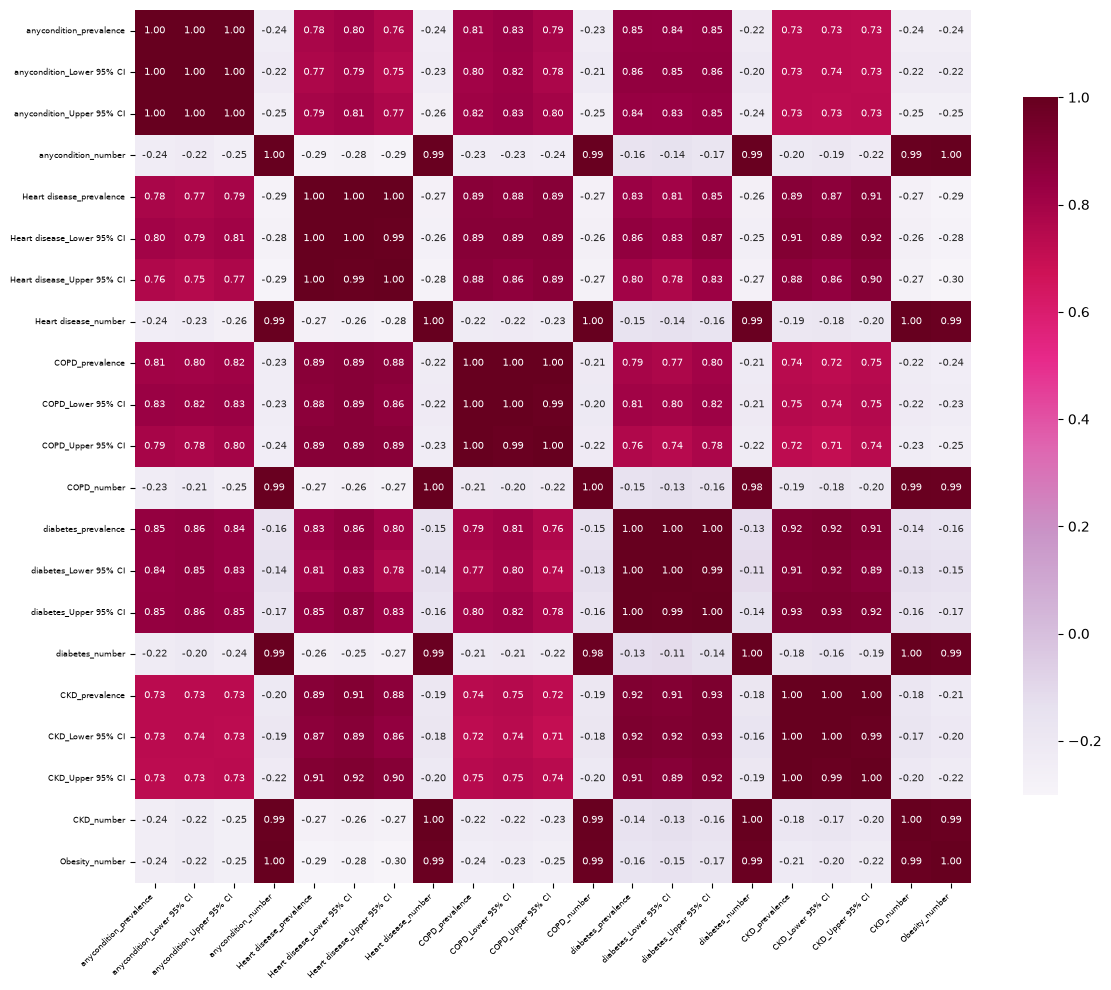

In [10]:
columnas_salud = ['anycondition_prevalence', 'anycondition_Lower 95% CI', 'anycondition_Upper 95% CI', 
             'anycondition_number', 'Heart disease_prevalence', 'Heart disease_Lower 95% CI',
             'Heart disease_Upper 95% CI', 'Heart disease_number', 'COPD_prevalence', 'COPD_Lower 95% CI',
             'COPD_Upper 95% CI', 'COPD_number', 'diabetes_prevalence', 'diabetes_Lower 95% CI', 
             'diabetes_Upper 95% CI', 'diabetes_number', 'CKD_prevalence', 'CKD_Lower 95% CI', 
             'CKD_Upper 95% CI', 'CKD_number', 'Obesity_number'
]                   
  
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df[columnas_salud].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax, annot_kws= {'size':7},
            cbar_kws= {'shrink': .8})

plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

Nos quedaremos solo con las columnas de salud de predominio (**_prevalence**).

In [11]:
df.drop(columns= ['anycondition_Lower 95% CI', 'anycondition_Upper 95% CI', 'anycondition_number',
                  'Heart disease_Lower 95% CI', 'Heart disease_Upper 95% CI', 'Heart disease_number',
                  'COPD_Lower 95% CI', 'COPD_Upper 95% CI', 'COPD_number', 'diabetes_Lower 95% CI',
                  'diabetes_Upper 95% CI', 'diabetes_number', 'CKD_Lower 95% CI', 'CKD_Upper 95% CI',
                  'CKD_number'
], inplace= True)

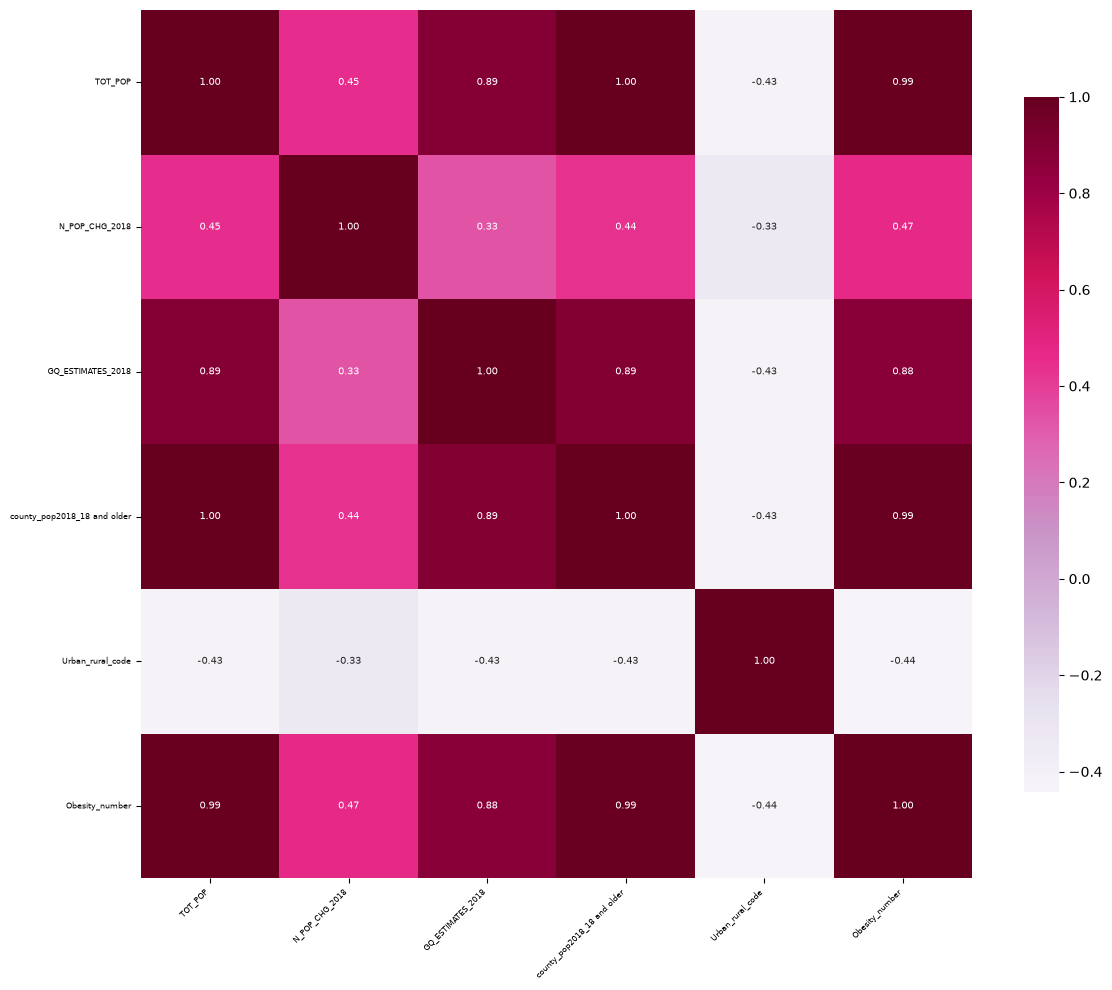

In [12]:
columnas_geo_pob = ['TOT_POP', 'N_POP_CHG_2018', 'GQ_ESTIMATES_2018', 'county_pop2018_18 and older',
                    'Urban_rural_code', 'Obesity_number'
]                   
  
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df[columnas_geo_pob].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax, annot_kws= {'size':7},
            cbar_kws= {'shrink': .8})

plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

De todas estas variables nos quedaremos unicamente con **'GQ_ESTIMATES_2018'** ya hay altisima correlación entre todas, y esa es la que mejor correlación tiene con nuestra objetivo (descartando las que tienen sobre 0.95).

In [13]:
df.drop(columns= ['TOT_POP', 'N_POP_CHG_2018', 'county_pop2018_18 and older', 'Urban_rural_code'
] , inplace= True)

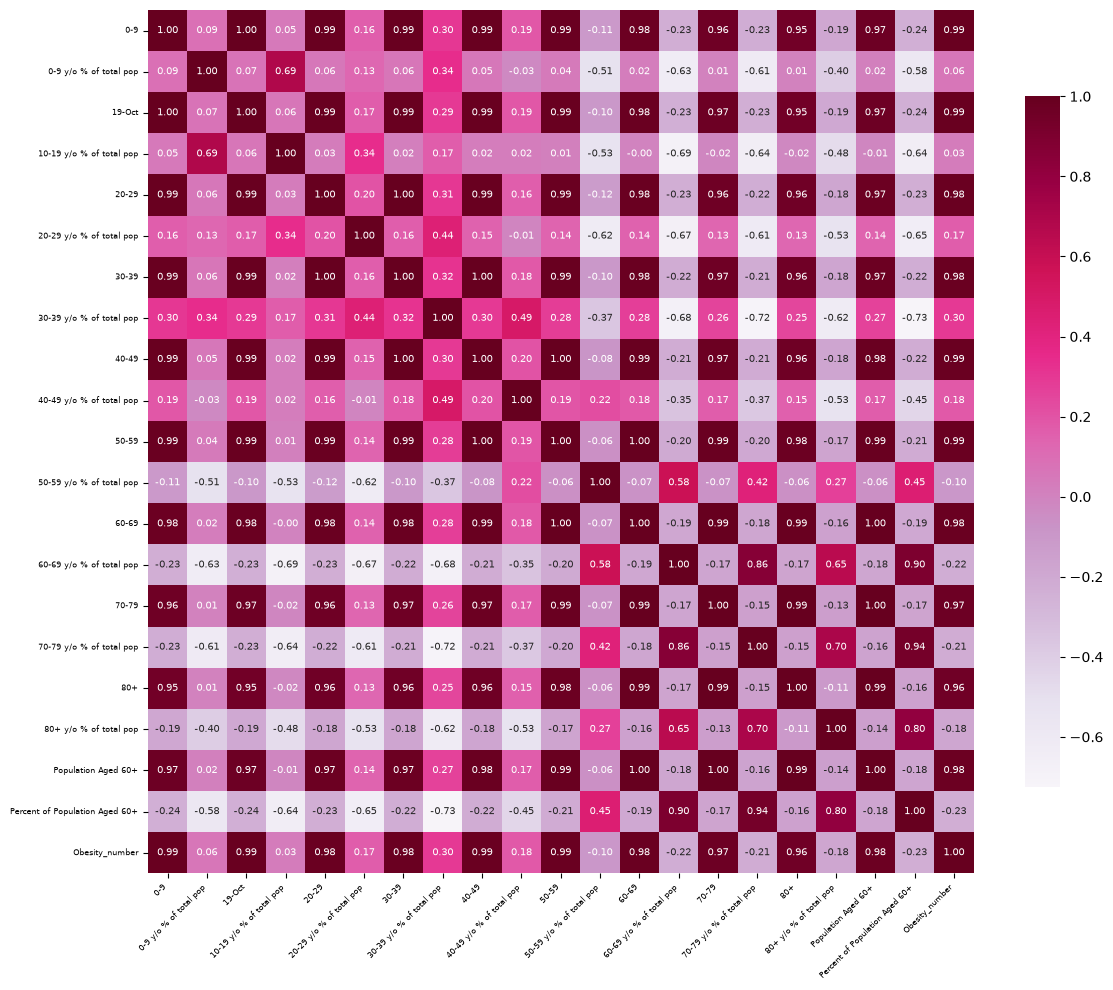

In [14]:
columnas_dist_edades = ['0-9', '0-9 y/o % of total pop', '19-Oct', '10-19 y/o % of total pop', '20-29',
                        '20-29 y/o % of total pop', '30-39', '30-39 y/o % of total pop', '40-49',
                        '40-49 y/o % of total pop', '50-59', '50-59 y/o % of total pop', '60-69',
                        '60-69 y/o % of total pop', '70-79', '70-79 y/o % of total pop',
                        '80+', '80+ y/o % of total pop', 'Population Aged 60+', 'Percent of Population Aged 60+',
                        'Obesity_number'
]                   
  
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df[columnas_dist_edades].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax, annot_kws= {'size':7},
            cbar_kws= {'shrink': .8})

plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

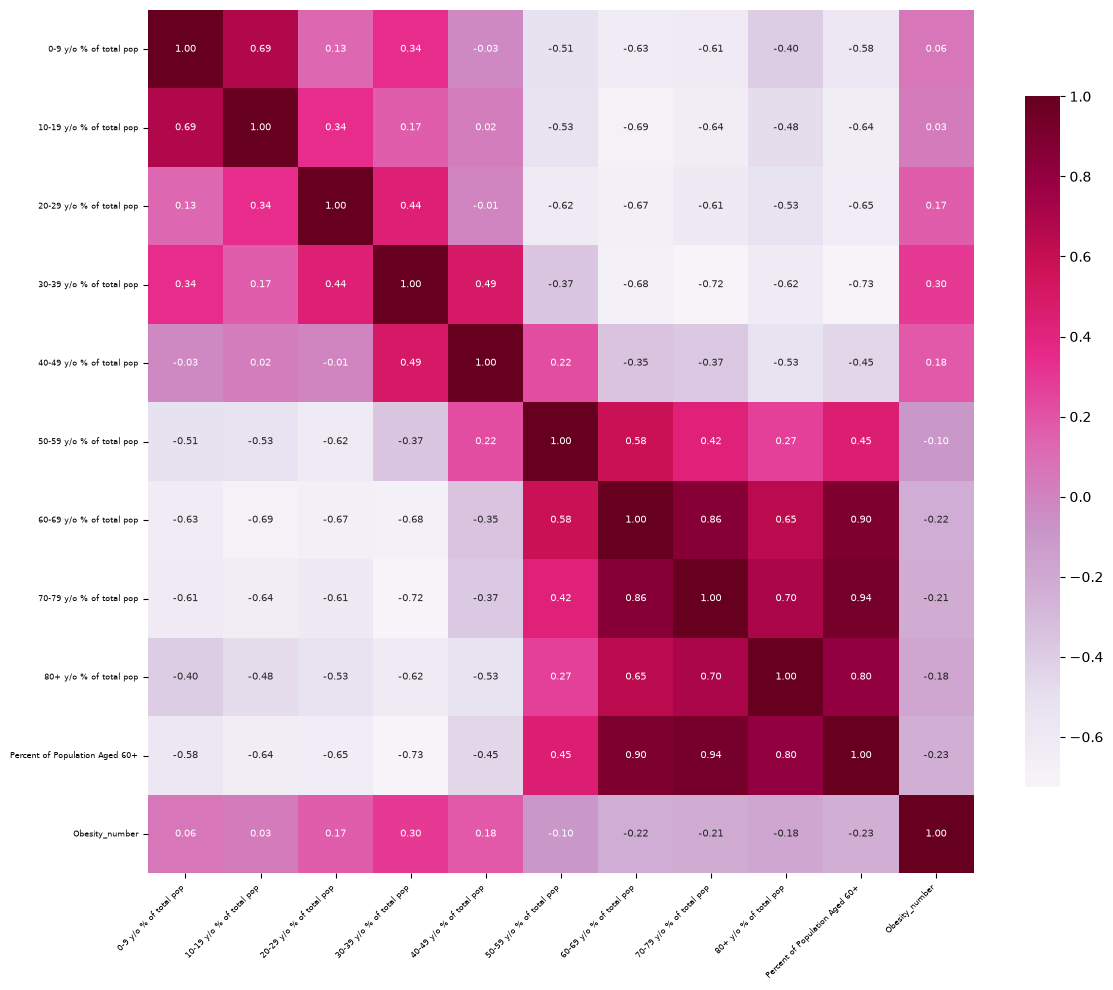

In [15]:
columnas_edades = ['0-9 y/o % of total pop', '10-19 y/o % of total pop', '20-29 y/o % of total pop',
                   '30-39 y/o % of total pop', '40-49 y/o % of total pop', '50-59 y/o % of total pop',
                   '60-69 y/o % of total pop', '70-79 y/o % of total pop', '80+ y/o % of total pop',
                   'Percent of Population Aged 60+', 'Obesity_number'
]                   
  
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df[columnas_edades].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax, annot_kws= {'size':7},
            cbar_kws= {'shrink': .8})

plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

Eliminaremos todas las columnas de distribución de edad debido a la alta multicolinealidad.

In [16]:
df.drop(columns= ['0-9', '0-9 y/o % of total pop','19-Oct', '10-19 y/o % of total pop','20-29',
                  '20-29 y/o % of total pop', '30-39', '30-39 y/o % of total pop', '40-49',
                  '40-49 y/o % of total pop', '50-59', '50-59 y/o % of total pop', '60-69',
                  '60-69 y/o % of total pop', '70-79', '70-79 y/o % of total pop', '80+', '80+ y/o % of total pop',
                  'Population Aged 60+', 'Percent of Population Aged 60+'
] , inplace= True)

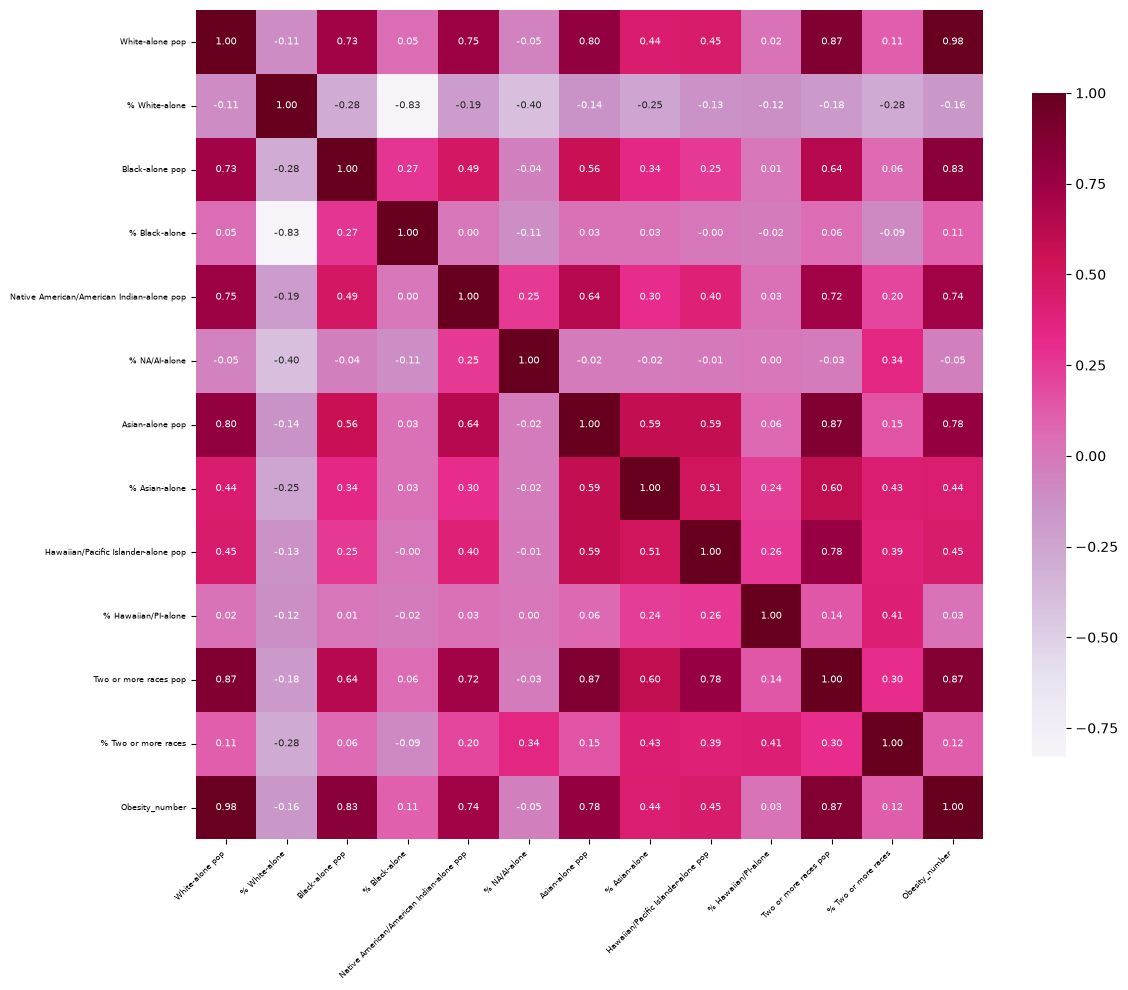

In [17]:
dist_racial_etnia = ['White-alone pop', '% White-alone', 'Black-alone pop', '% Black-alone',
                    'Native American/American Indian-alone pop', '% NA/AI-alone',
                    'Asian-alone pop', '% Asian-alone', 'Hawaiian/Pacific Islander-alone pop',
                    '% Hawaiian/PI-alone', 'Two or more races pop', '% Two or more races', 'Obesity_number'
]                   
  
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df[dist_racial_etnia].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax, annot_kws= {'size':7},
            cbar_kws= {'shrink': .8})

plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

Eliminaremos todas las columnas de distribución racial y étnica debido a la alta multicolinealidad.

In [18]:
df.drop(columns= ['White-alone pop', '% White-alone', 'Black-alone pop', '% Black-alone',
                    'Native American/American Indian-alone pop', '% NA/AI-alone',
                    'Asian-alone pop', '% Asian-alone', 'Hawaiian/Pacific Islander-alone pop',
                    '% Hawaiian/PI-alone', 'Two or more races pop', '% Two or more races'
] , inplace= True)

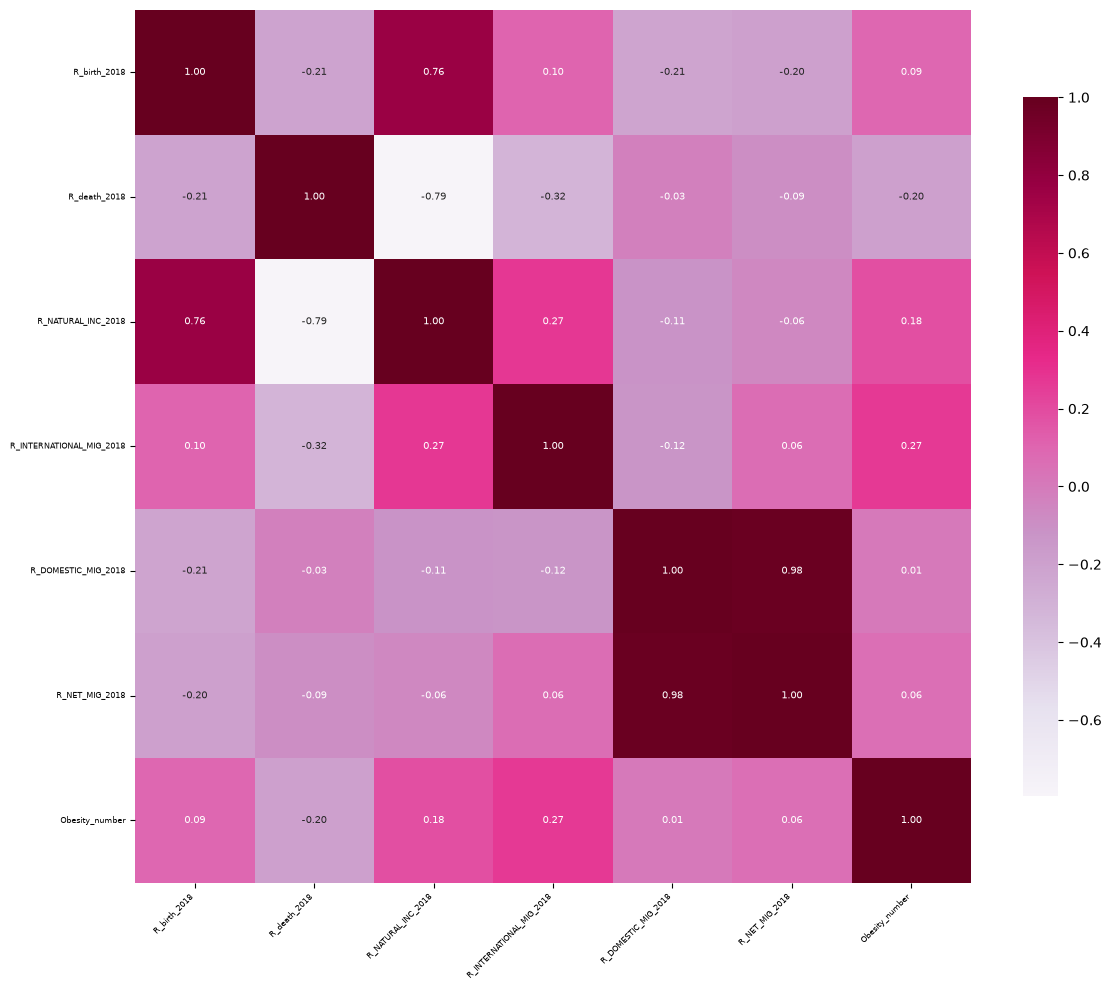

In [19]:
tasa_dem_mig_2018 = ['R_birth_2018', 'R_death_2018', 'R_NATURAL_INC_2018', 'R_INTERNATIONAL_MIG_2018',
                    'R_DOMESTIC_MIG_2018', 'R_NET_MIG_2018', 'Obesity_number'
]                   
  
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df[tasa_dem_mig_2018].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax, annot_kws= {'size':7},
            cbar_kws= {'shrink': .8})

plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

De todas estas variables, nos quedaremos con **'R_INTERNATIONAL_MIG_2018'** que es la que mejor correlación tiene con nuestra objetivo.

In [20]:
df.drop(columns= ['R_birth_2018', 'R_death_2018', 'R_NATURAL_INC_2018', 'R_DOMESTIC_MIG_2018', 'R_NET_MIG_2018'
] , inplace= True)

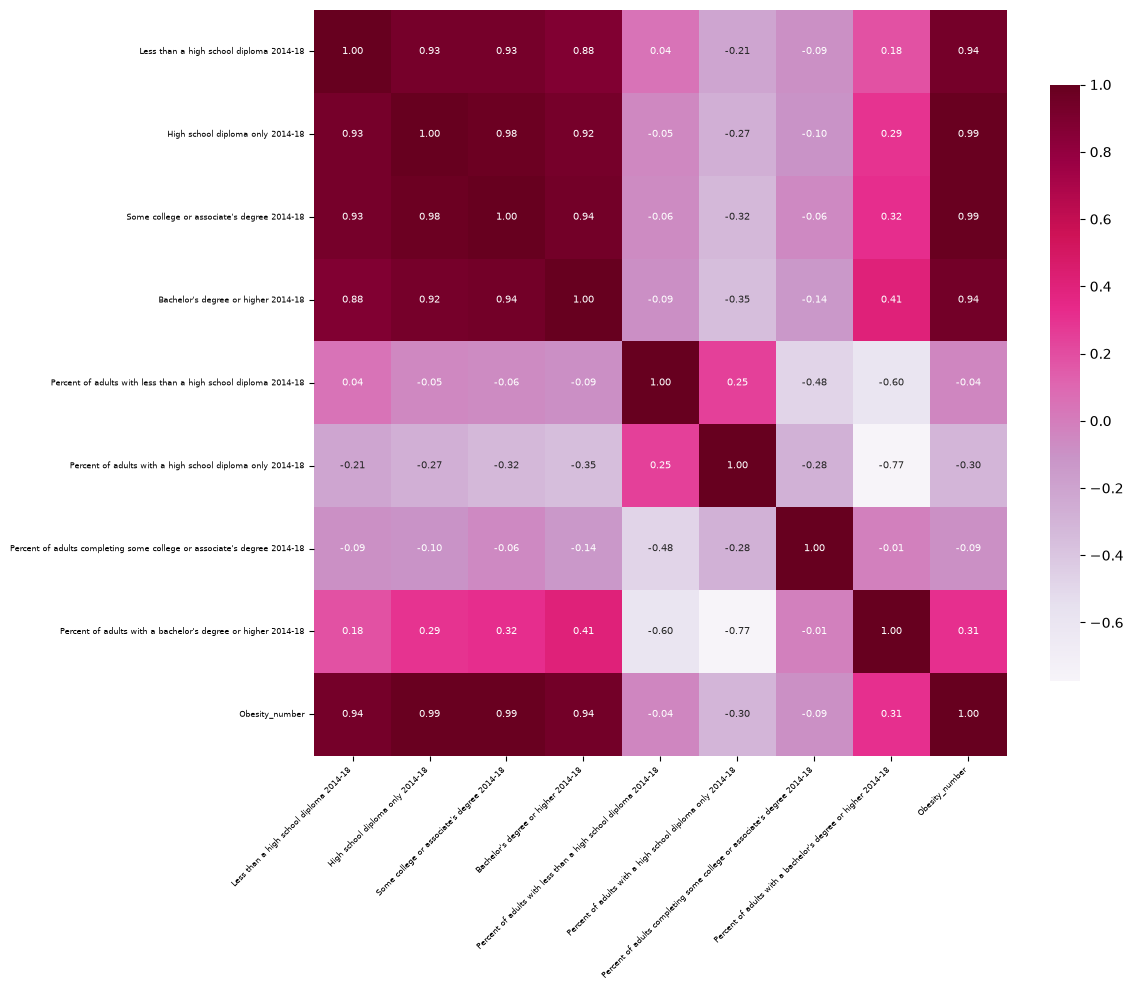

In [21]:
nivel_educativo = ["Less than a high school diploma 2014-18", "High school diploma only 2014-18",
                   "Some college or associate's degree 2014-18", "Bachelor's degree or higher 2014-18",
                   "Percent of adults with less than a high school diploma 2014-18",
                   "Percent of adults with a high school diploma only 2014-18",
                   "Percent of adults completing some college or associate's degree 2014-18",
                   "Percent of adults with a bachelor's degree or higher 2014-18", "Obesity_number"
]                   
  
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df[nivel_educativo].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax, annot_kws= {'size':7},
            cbar_kws= {'shrink': .8})

plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

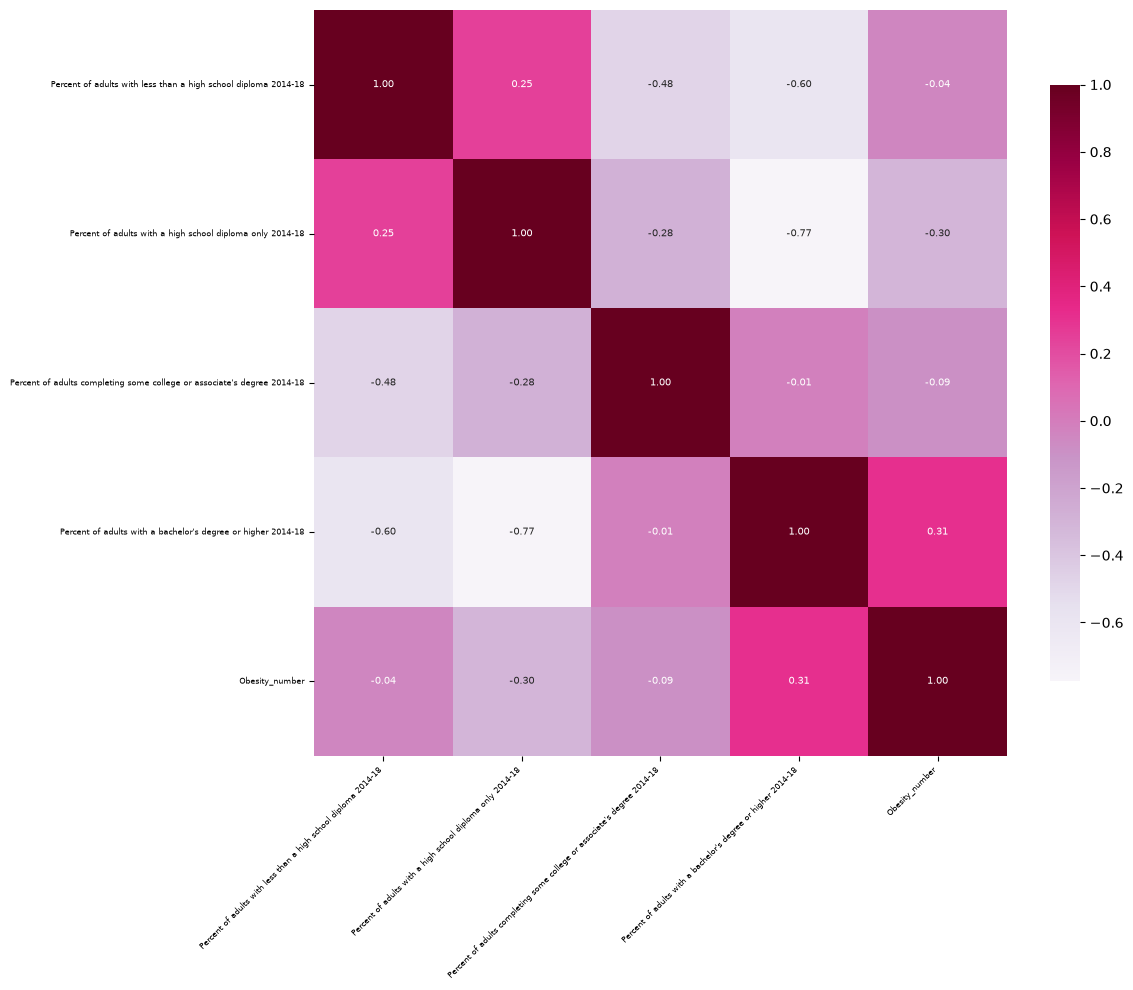

In [22]:
nivel_educativo = ["Percent of adults with less than a high school diploma 2014-18",
                   "Percent of adults with a high school diploma only 2014-18",
                   "Percent of adults completing some college or associate's degree 2014-18",
                   "Percent of adults with a bachelor's degree or higher 2014-18", "Obesity_number"
]                   
  
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df[nivel_educativo].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax, annot_kws= {'size':7},
            cbar_kws= {'shrink': .8})

plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

Las eliminaremos todas debido a la alta correlación que tienen entre ellas.

In [23]:
df.drop(columns= ["Less than a high school diploma 2014-18", "High school diploma only 2014-18",
                  "Some college or associate's degree 2014-18", "Bachelor's degree or higher 2014-18"
] , inplace= True)

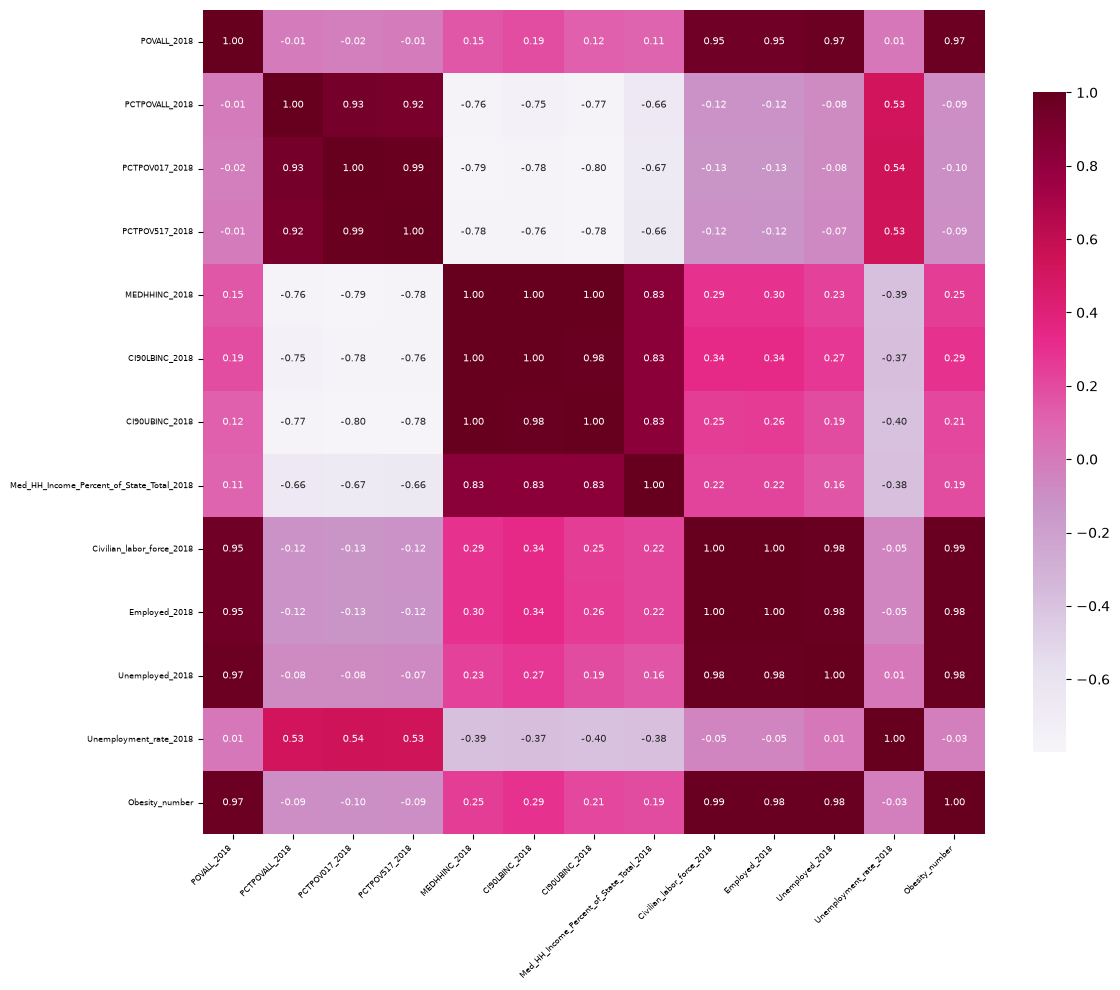

In [24]:
econ_pobr_ing = ['POVALL_2018', 'PCTPOVALL_2018', 'PCTPOV017_2018', 'PCTPOV517_2018', 'MEDHHINC_2018',
                 'CI90LBINC_2018', 'CI90UBINC_2018', 'Med_HH_Income_Percent_of_State_Total_2018',
                 'Civilian_labor_force_2018', 'Employed_2018', 'Unemployed_2018', 'Unemployment_rate_2018',
                 'Obesity_number'
]                   
  
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df[econ_pobr_ing].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax, annot_kws= {'size':7},
            cbar_kws= {'shrink': .8})

plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

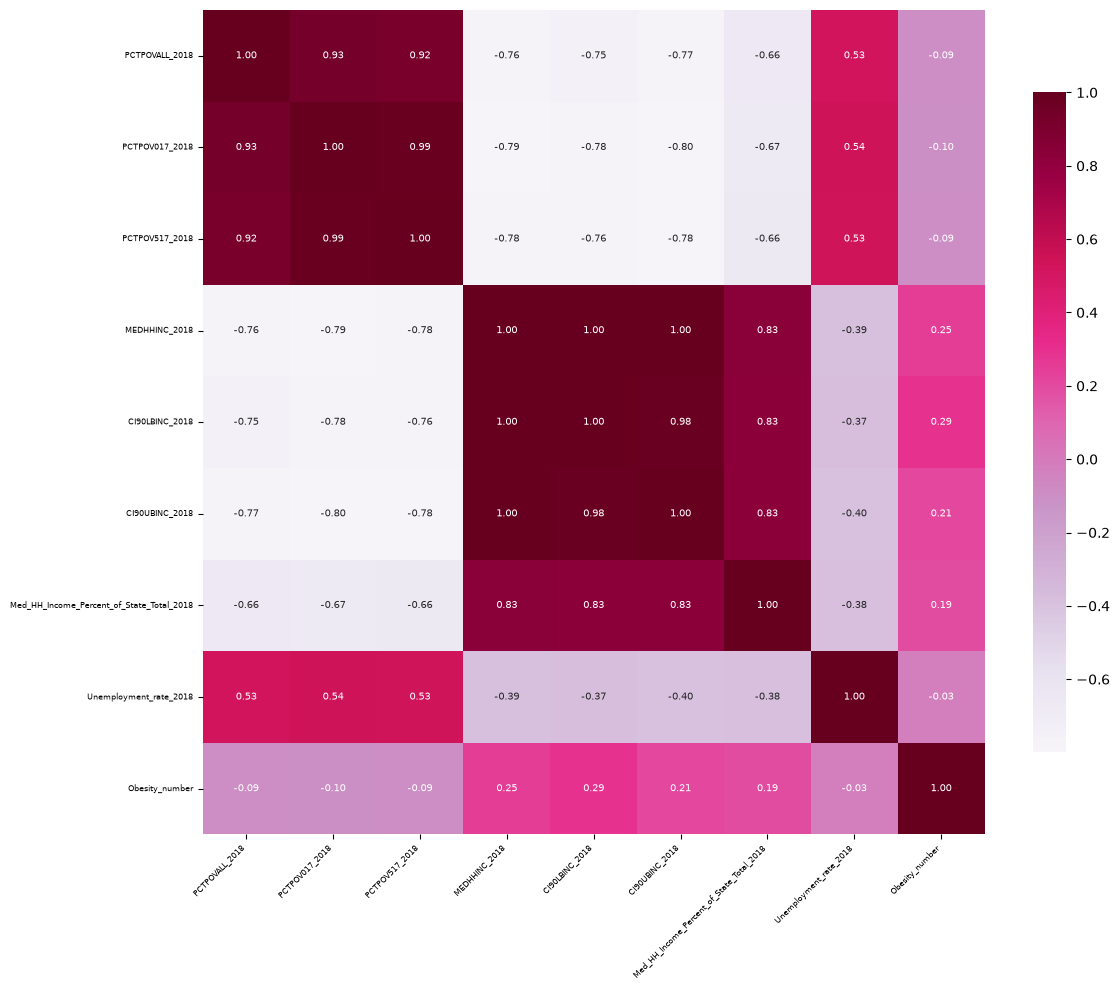

In [25]:
econ_pobr_ing_avanzado = ['PCTPOVALL_2018', 'PCTPOV017_2018', 'PCTPOV517_2018', 'MEDHHINC_2018',
                 'CI90LBINC_2018', 'CI90UBINC_2018', 'Med_HH_Income_Percent_of_State_Total_2018',
                 'Unemployment_rate_2018', 'Obesity_number'
]                   
  
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df[econ_pobr_ing_avanzado].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax, annot_kws= {'size':7},
            cbar_kws= {'shrink': .8})

plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

Tambien las eliminaremos todas, debido a la alta correlación entre ellas.

In [26]:
df.drop(columns= ['POVALL_2018', 'PCTPOVALL_2018', 'PCTPOV017_2018', 'PCTPOV517_2018', 'MEDHHINC_2018',
                 'CI90LBINC_2018', 'CI90UBINC_2018', 'Med_HH_Income_Percent_of_State_Total_2018',
                 'Civilian_labor_force_2018', 'Employed_2018', 'Unemployed_2018', 'Unemployment_rate_2018'
]  , inplace= True)

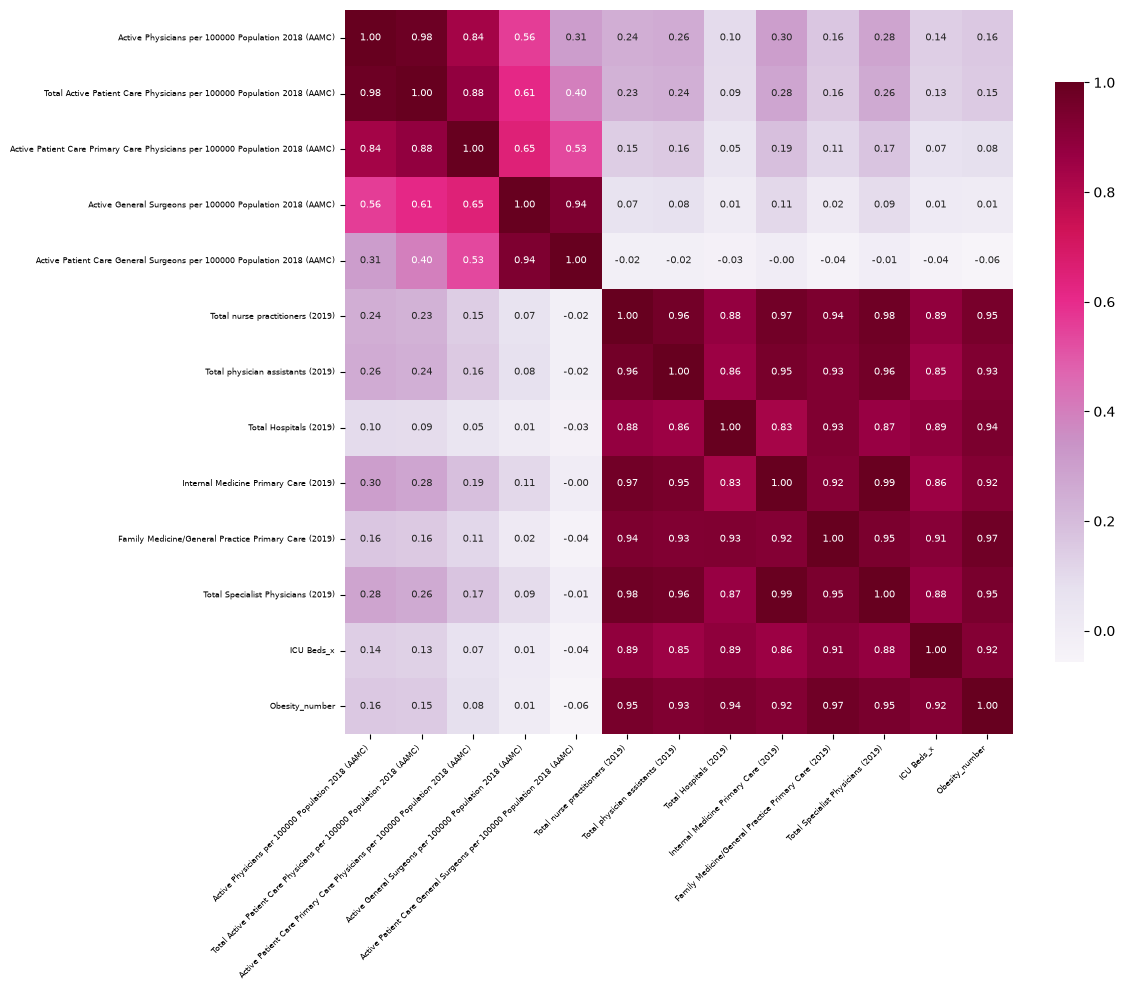

In [27]:
infra_medica = ['Active Physicians per 100000 Population 2018 (AAMC)',
                'Total Active Patient Care Physicians per 100000 Population 2018 (AAMC)',
                'Active Patient Care Primary Care Physicians per 100000 Population 2018 (AAMC)',
                'Active General Surgeons per 100000 Population 2018 (AAMC)',
                'Active Patient Care General Surgeons per 100000 Population 2018 (AAMC)',
                'Total nurse practitioners (2019)', 'Total physician assistants (2019)',
                'Total Hospitals (2019)', 'Internal Medicine Primary Care (2019)',
                'Family Medicine/General Practice Primary Care (2019)',
                'Total Specialist Physicians (2019)', 'ICU Beds_x', 'Obesity_number'
]                   
  
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df[infra_medica].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax, annot_kws= {'size':7},
            cbar_kws= {'shrink': .8})

plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

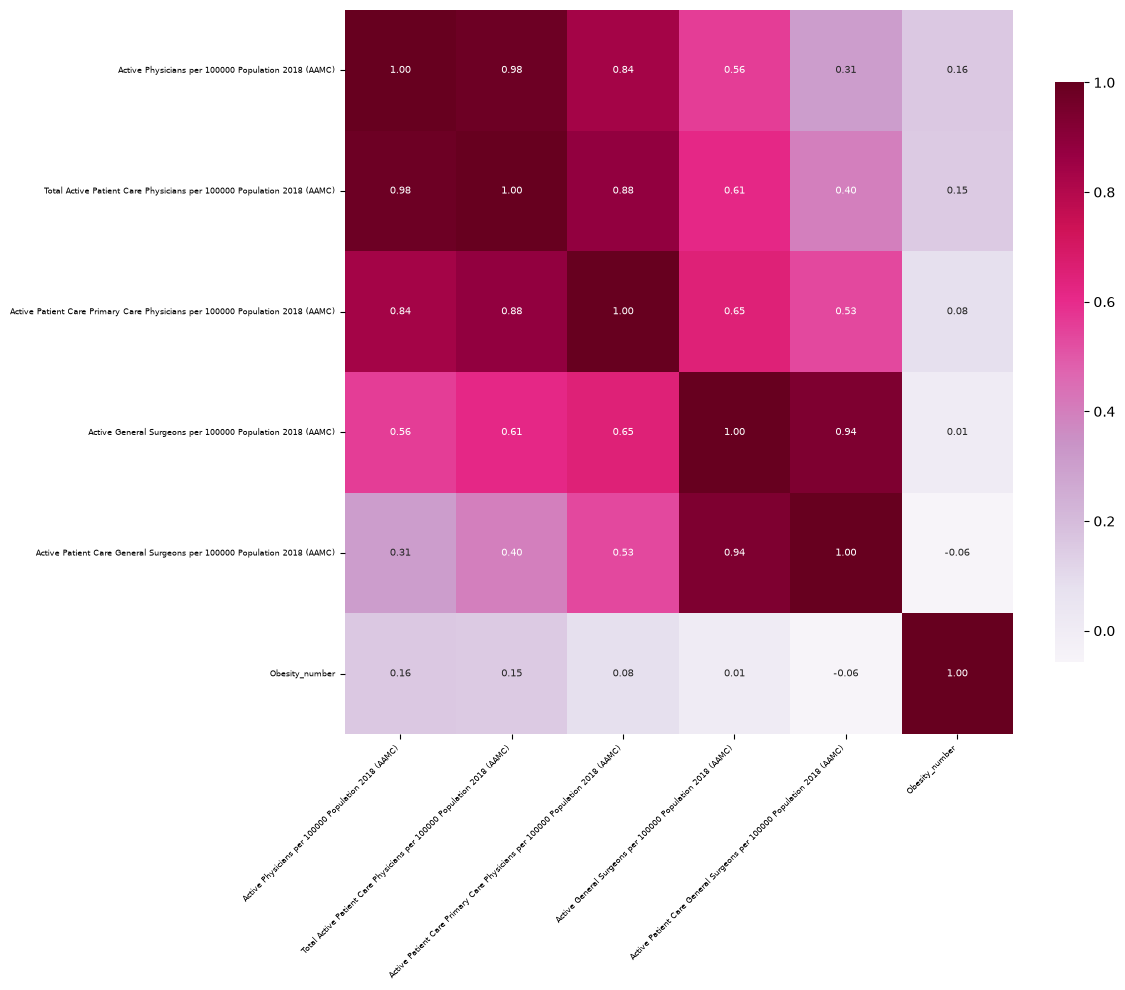

In [28]:
infra_medica_ = ['Active Physicians per 100000 Population 2018 (AAMC)',
                'Total Active Patient Care Physicians per 100000 Population 2018 (AAMC)',
                'Active Patient Care Primary Care Physicians per 100000 Population 2018 (AAMC)',
                'Active General Surgeons per 100000 Population 2018 (AAMC)',
                'Active Patient Care General Surgeons per 100000 Population 2018 (AAMC)',
                'Obesity_number'
]                   
  
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df[infra_medica_].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax, annot_kws= {'size':7},
            cbar_kws= {'shrink': .8})

plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

Las eliminaremos todas debido a su alta correlación entre ellas y además su poca correlación con nuestra objetivo.

In [29]:
df.drop(columns= ['Active Physicians per 100000 Population 2018 (AAMC)',
                'Total Active Patient Care Physicians per 100000 Population 2018 (AAMC)',
                'Active Patient Care Primary Care Physicians per 100000 Population 2018 (AAMC)',
                'Active General Surgeons per 100000 Population 2018 (AAMC)',
                'Active Patient Care General Surgeons per 100000 Population 2018 (AAMC)',
                'Total nurse practitioners (2019)', 'Total physician assistants (2019)',
                'Total Hospitals (2019)', 'Internal Medicine Primary Care (2019)',
                'Family Medicine/General Practice Primary Care (2019)',
                'Total Specialist Physicians (2019)', 'ICU Beds_x'
] , inplace= True)

In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3140 entries, 0 to 3139
Data columns (total 17 columns):
 #   Column                                                                   Non-Null Count  Dtype  
---  ------                                                                   --------------  -----  
 0   POP_ESTIMATE_2018                                                        3140 non-null   int64  
 1   GQ_ESTIMATES_2018                                                        3140 non-null   int64  
 2   R_INTERNATIONAL_MIG_2018                                                 3140 non-null   float64
 3   Percent of adults with less than a high school diploma 2014-18           3140 non-null   float64
 4   Percent of adults with a high school diploma only 2014-18                3140 non-null   float64
 5   Percent of adults completing some college or associate's degree 2014-18  3140 non-null   float64
 6   Percent of adults with a bachelor's degree or higher 2014-18             3140 non-n

Nuestro dataset ya esta reducido a 17 columnas, por lo que haremos otra matriz de correlación con estas 17.

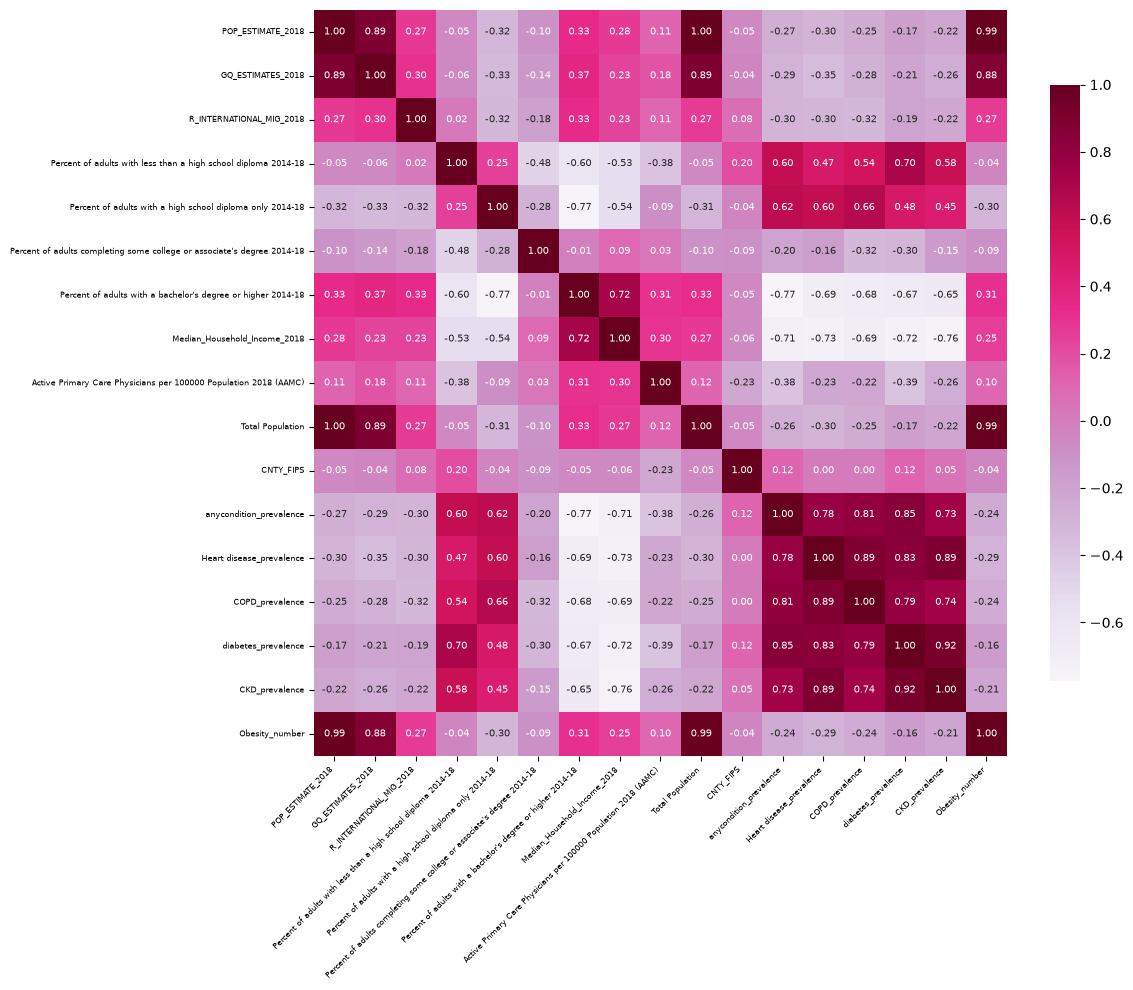

In [31]:
df_reducido = ["POP_ESTIMATE_2018", "GQ_ESTIMATES_2018", "R_INTERNATIONAL_MIG_2018",
               "Percent of adults with less than a high school diploma 2014-18",
               "Percent of adults with a high school diploma only 2014-18",
               "Percent of adults completing some college or associate's degree 2014-18",
               "Percent of adults with a bachelor's degree or higher 2014-18",
               "Median_Household_Income_2018", "Active Primary Care Physicians per 100000 Population 2018 (AAMC)",
               "Total Population", "CNTY_FIPS", "anycondition_prevalence", "Heart disease_prevalence",
               "COPD_prevalence", "diabetes_prevalence", "CKD_prevalence", "Obesity_number"
]                   
  
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df[df_reducido].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax, annot_kws= {'size':7},
            cbar_kws= {'shrink': .8})

plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

Eliminaremos **'POP_ESTIMATE_2018'** y **'Total_Population'** por tener una correlación de 0.99 cada una con nuestra objetivo.

In [32]:
df.drop(columns= ["POP_ESTIMATE_2018", "Total Population"
] , inplace= True)

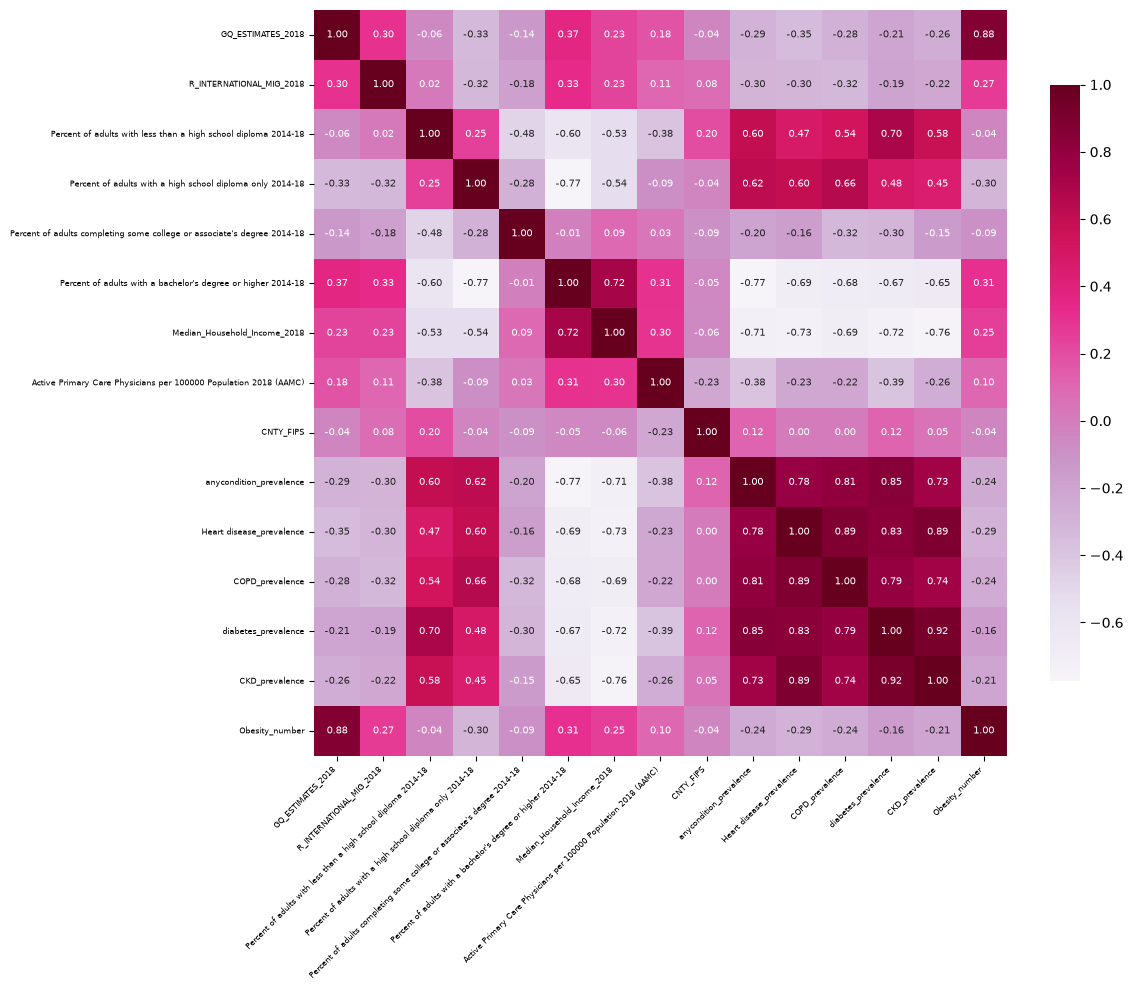

In [33]:
df_reducido = ["GQ_ESTIMATES_2018", "R_INTERNATIONAL_MIG_2018",
               "Percent of adults with less than a high school diploma 2014-18",
               "Percent of adults with a high school diploma only 2014-18",
               "Percent of adults completing some college or associate's degree 2014-18",
               "Percent of adults with a bachelor's degree or higher 2014-18",
               "Median_Household_Income_2018", "Active Primary Care Physicians per 100000 Population 2018 (AAMC)",
               "CNTY_FIPS", "anycondition_prevalence", "Heart disease_prevalence",
               "COPD_prevalence", "diabetes_prevalence", "CKD_prevalence", "Obesity_number"
]                   
  
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df[df_reducido].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax, annot_kws= {'size':7},
            cbar_kws= {'shrink': .8})

plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

Entre todas las variables que nos quedan relacionadas con la salud, nos quedaremos solo con **'Heart disease_prevalence'** ya que entre todas tienen mucha correlación, y ésta tiene la mayor correlación con nuestra objetivo. Y también eliminaremos las variables que tienen una correlación baja-casi nula con nuestra objetivo: **'Percent of adults with less than a high school diploma 2014-18'**, **'Percent of adults completing some college or associate's degree 2014-18'**, **'Active Primary Care Physicians per 100000 Population 2018 (AAMC)'** y **'CNTY_FIPS'**.

In [34]:
df.drop(columns= ["anycondition_prevalence", "COPD_prevalence", "diabetes_prevalence", "CKD_prevalence",
                  "Percent of adults with less than a high school diploma 2014-18",
                  "Percent of adults completing some college or associate's degree 2014-18",
                  "Active Primary Care Physicians per 100000 Population 2018 (AAMC)", "CNTY_FIPS"
] , inplace= True)

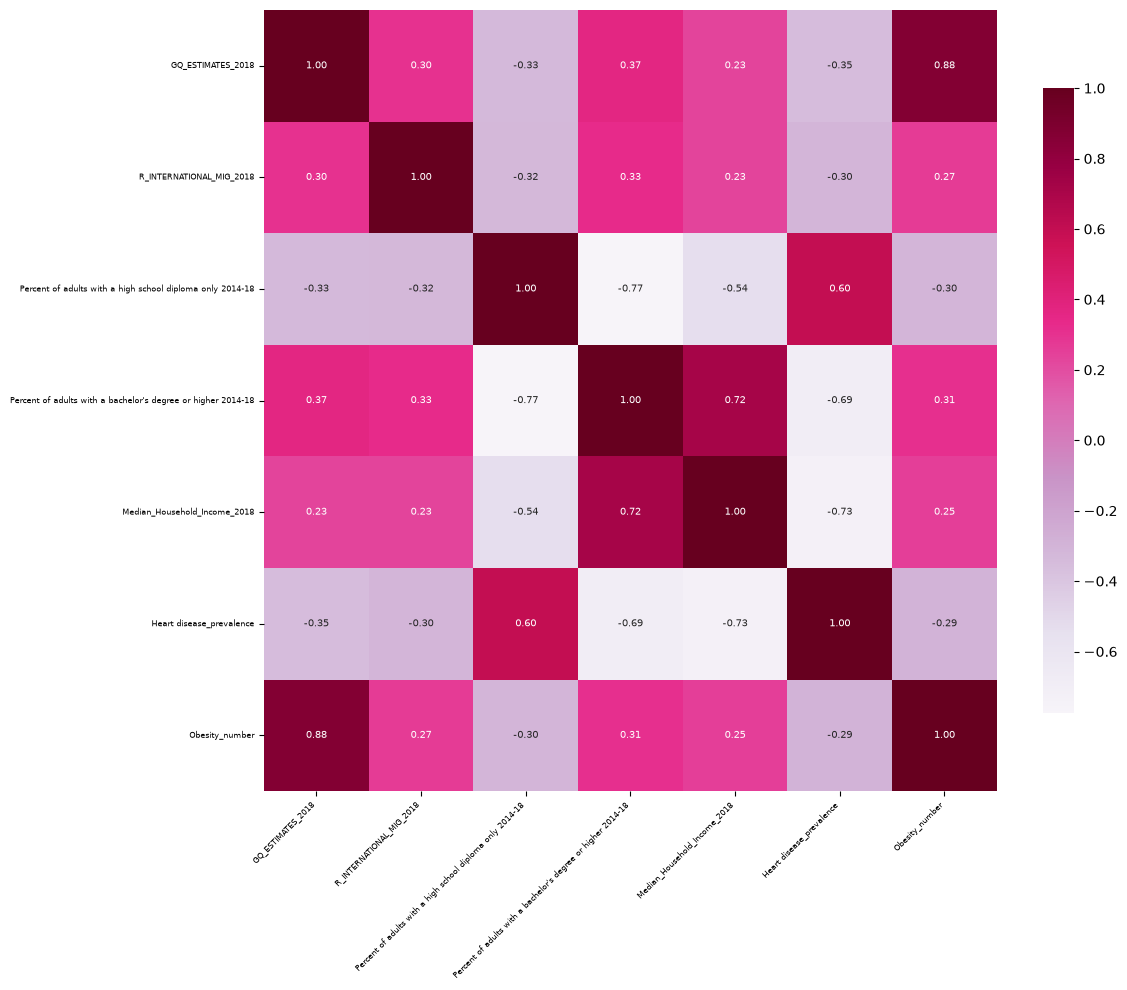

In [35]:
df_reducido = ["GQ_ESTIMATES_2018", "R_INTERNATIONAL_MIG_2018",
               "Percent of adults with a high school diploma only 2014-18",
               "Percent of adults with a bachelor's degree or higher 2014-18",
               "Median_Household_Income_2018", "Heart disease_prevalence", "Obesity_number"
]                   
  
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df[df_reducido].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax, annot_kws= {'size':7},
            cbar_kws= {'shrink': .8})

plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

Eliminaremos **'Percent of adults with a high school diploma only 2014-18'** por tener una alta correlación con **'Percent of adults with a bachelor's degree or higher 2014-18'**, también eliminaremos **'Median_Household_Income_2018'** por tener una alta correlación con **'Heart disease_prevalence'**.

In [36]:
df.drop(columns= ["Percent of adults with a high school diploma only 2014-18", "Median_Household_Income_2018"
] , inplace= True)

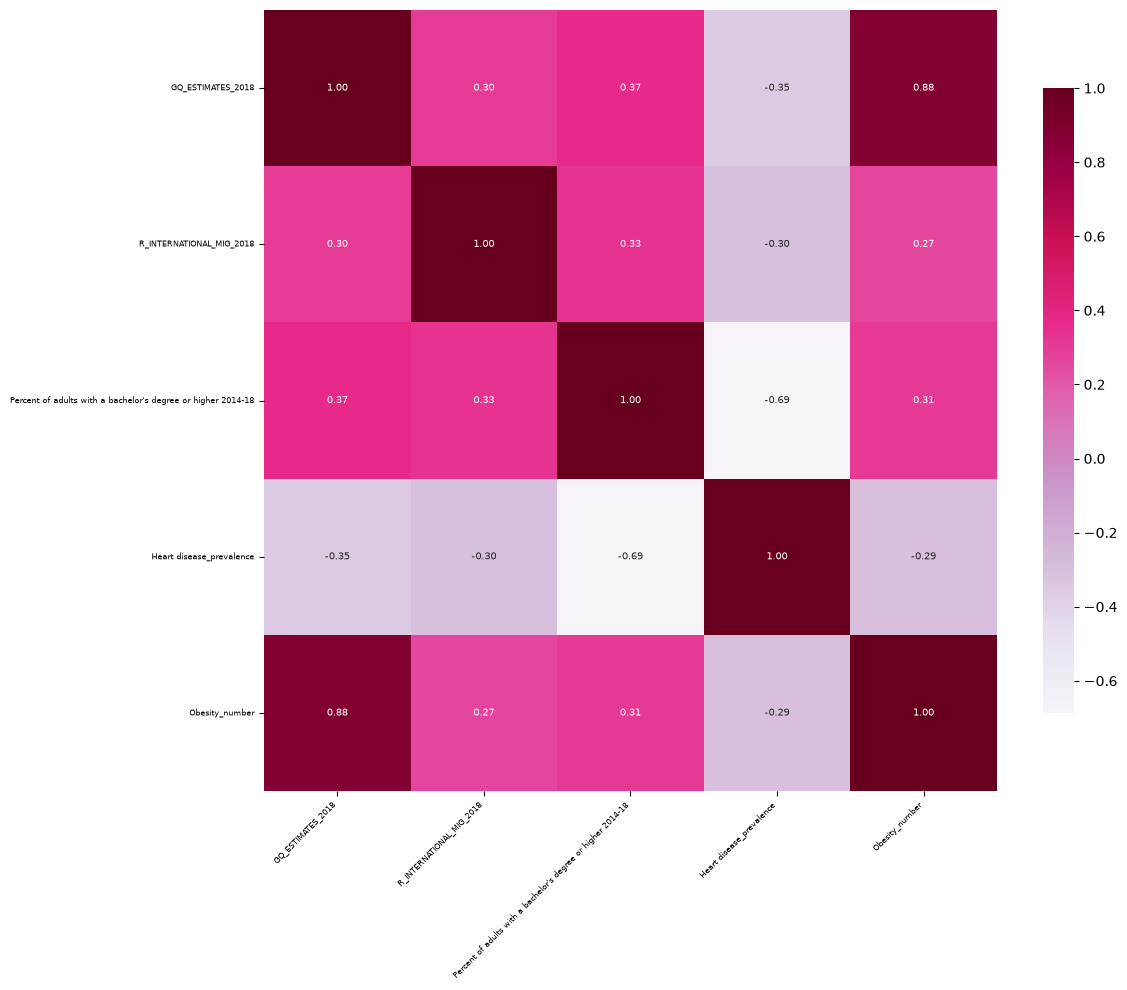

In [37]:
df_reducido = ["GQ_ESTIMATES_2018", "R_INTERNATIONAL_MIG_2018",
               "Percent of adults with a bachelor's degree or higher 2014-18", "Heart disease_prevalence", 
               "Obesity_number"
]                   
  
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(df[df_reducido].corr(method="pearson"), annot=True, fmt=".2f", cmap="PuRd", ax=ax, annot_kws= {'size':7},
            cbar_kws= {'shrink': .8})

plt.xticks(rotation=45, ha='right', fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.tight_layout()
plt.show()

Ya me quedan solo 4 variables independientes: **'GQ_ESTIMATES_2018'**, **'R_INTERNATIONAL_MIG_2018'**, **'Percent of adults with a bachelor's degree or higher 2014-18'**, **'Heart disease_prevalence'** y nuestra variable objetivo **'Obesity_number'**

### 4to Paso EDA: Análisis univariante

**Numérico**

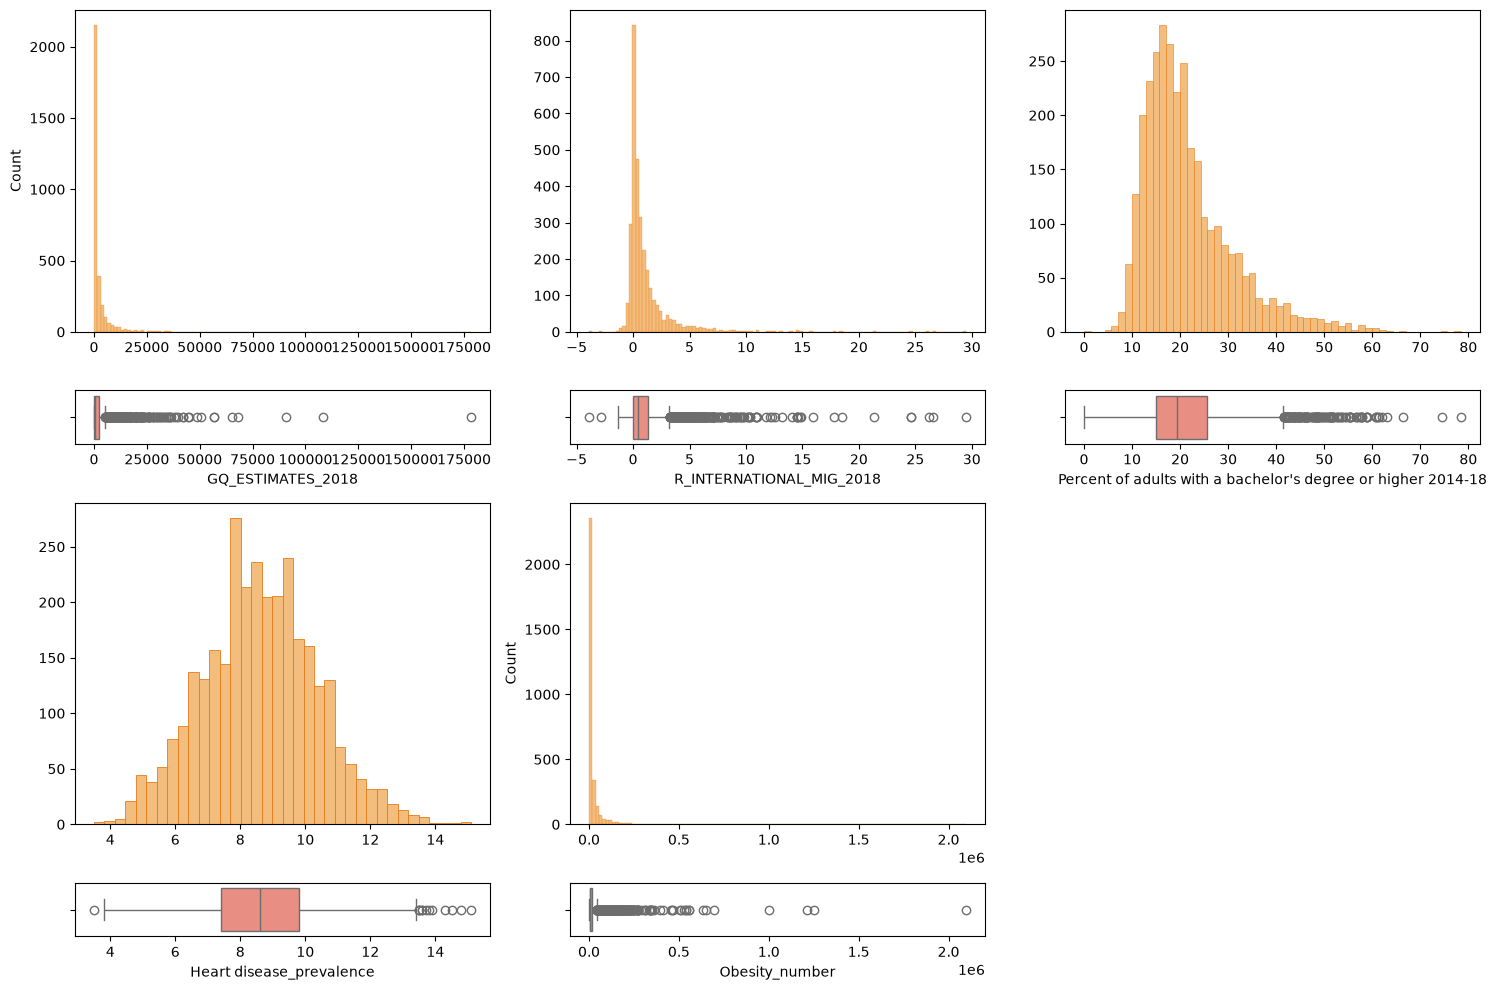

In [40]:
fig, axis = plt.subplots(4, 3, figsize = (15, 10), gridspec_kw={'height_ratios': [6, 1, 6, 1]})

sns.histplot(ax = axis[0, 0], data = df, x = "GQ_ESTIMATES_2018", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None)
sns.boxplot(ax = axis[1, 0], data = df, x = "GQ_ESTIMATES_2018", color='salmon')
sns.histplot(ax = axis[0, 1], data = df, x = "R_INTERNATIONAL_MIG_2018", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[1, 1], data = df, x = "R_INTERNATIONAL_MIG_2018", color='salmon')
sns.histplot(ax = axis[0, 2], data = df, x = "Percent of adults with a bachelor's degree or higher 2014-18", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[1, 2], data = df, x = "Percent of adults with a bachelor's degree or higher 2014-18", color='salmon')
sns.histplot(ax = axis[2, 0], data = df, x = "Heart disease_prevalence", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[3, 0], data = df, x = "Heart disease_prevalence", color='salmon')
sns.histplot(ax = axis[2, 1], data = df, x = "Obesity_number", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None)
sns.boxplot(ax = axis[3, 1], data = df, x = "Obesity_number", color='salmon')

fig.delaxes(axis[2, 2])
fig.delaxes(axis[3, 2])

plt.tight_layout()

plt.show()

### 5to Paso EDA: Ingeniería de Características

**Separación Train y Test**

In [43]:
X= df.drop(columns=['Obesity_number']) 
y= df['Obesity_number']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train.head()

,GQ_ESTIMATES_2018,R_INTERNATIONAL_MIG_2018,Percent of adults with a bachelor's degree or higher 2014-18,Heart disease_prevalence
1292,303,1.5,18.8,10.1
2302,1302,0.0,17.6,9.2
761,5022,0.6,16.1,7.3
2194,1216,0.5,24.3,7.8
1241,4326,2.3,21.2,8.4


**Escalado de valores**

Usaremos un escalado mínimo-máximo ya que no todas nuestras variables distribuyen normal.

In [45]:
scaler= MinMaxScaler()

X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

X_train_esc = pd.DataFrame(X_train_esc, columns=X_train.columns, index=X_train.index)
X_test_esc = pd.DataFrame(X_test_esc, columns=X_test.columns, index=X_test.index)

## Paso 3: Construye un modelo de regresión

In [47]:
modelo_rl = LinearRegression()
modelo_l = Lasso()
modelo_r = Ridge()

modelo_rl.fit(X_train_esc, y_train)
modelo_l.fit(X_train_esc, y_train)
modelo_r.fit(X_train_esc, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [49]:
y_pred_rl = modelo_rl.predict(X_test_esc)
y_pred_l = modelo_l.predict(X_test_esc)
y_pred_r = modelo_r.predict(X_test_esc)

print(y_pred_rl)
print(y_pred_l)
print(y_pred_r)

[ 1.69771825e+04  8.99050805e+04  2.17684271e+04  8.77953839e+03
  5.49044302e+04  9.44513152e+03  2.82830629e+03  1.24574559e+04
  6.33041833e+00  3.88543304e+04  8.31717877e+03  1.87981477e+03
  5.41050233e+04  1.19365069e+04  7.91677207e+04  1.67833524e+04
  2.05605298e+05  2.81950763e+03  8.69147682e+03  6.22186086e+03
  3.69945055e+03  8.31877322e+03  3.67541723e+03  1.89527927e+02
  4.17162248e+05  1.65446994e+03 -4.18922505e+03  5.43580090e+03
  3.70749539e+03  1.04209294e+03  2.25201921e+03  4.20163430e+04
  3.32129823e+03  7.97157224e+03  9.70574033e+03  6.42635311e+03
  5.10098842e+03  3.22787820e+03  3.43448869e+04  9.51356425e+03
  4.58058513e+03  3.61539785e+04  9.12177571e+02 -4.62155576e+02
  2.10219043e+03  1.55913168e+03  6.87382033e+02  2.17771426e+04
  3.23969047e+03  2.39715172e+03  4.69221546e+04  2.93638303e+03
  6.05234231e+03  2.87468182e+03  1.00152504e+05  2.48689673e+03
  2.60654996e+05  1.87029598e+03  3.54527393e+04  2.78657981e+03
  4.32819125e+04  2.44406

In [51]:
print(f'Modelo Regresión Lineal')
print(f'RMSE: {root_mean_squared_error(y_test,y_pred_rl)}')
print(f'R2: {r2_score(y_test,y_pred_rl)}')

print(f'Modelo Lasso')
print(f'RMSE: {root_mean_squared_error(y_test,y_pred_l)}')
print(f'R2: {r2_score(y_test,y_pred_l)}')

print(f'Modelo Ridge')
print(f'RMSE: {root_mean_squared_error(y_test,y_pred_r)}')
print(f'R2: {r2_score(y_test,y_pred_r)}')


Modelo Regresión Lineal
RMSE: 22938.46925168804
R2: 0.7593633334292319
Modelo Lasso
RMSE: 22932.497162219002
R2: 0.759488617868198
Modelo Ridge
RMSE: 22596.194093615606
R2: 0.7664910504100335


In [53]:
df_coeficientes_lasso = pd.DataFrame({'Variable': X_train_esc.columns,
                                      'Coeficiente':modelo_l.coef_,
                                      'Magnitud':np.abs(modelo_l.coef_)}
)

df_coeficientes_lasso_no0 = df_coeficientes_lasso[df_coeficientes_lasso['Magnitud']>0]

print(df_coeficientes_lasso_no0.sort_values(by='Magnitud', ascending =False))

                                            Variable   Coeficiente  \
0                                  GQ_ESTIMATES_2018  1.763008e+06   
1                           R_INTERNATIONAL_MIG_2018  1.075566e+04   
2  Percent of adults with a bachelor's degree or ... -8.447510e+03   
3                           Heart disease_prevalence  3.220710e+03   

       Magnitud  
0  1.763008e+06  
1  1.075566e+04  
2  8.447510e+03  
3  3.220710e+03  


In [54]:
print(len(df_coeficientes_lasso_no0.sort_values(by='Magnitud', ascending =False)))

4


In [55]:
alphas = np.linspace(0, 20, 100)
r2s = []
l_alphas = []

for alpha in alphas:
    model_alpha = Lasso(alpha=alpha)
    model_alpha.fit(X_train_esc, y_train)
    y_pred_alpha = model_alpha.predict(X_test_esc)
    r2s.append(r2_score(y_test, y_pred_alpha))
    l_alphas.append(alpha)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/base.py:1403: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)


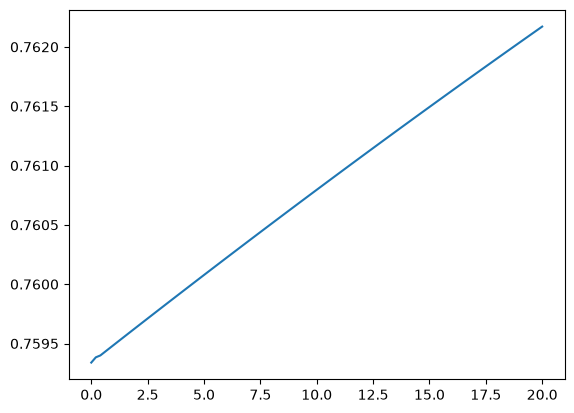

In [56]:
plt.plot(l_alphas,r2s)
plt.show()